# Procrastinación y entregas de tareas en Mediación Virtual
**MA-0321 · Proyecto Aplicado 2 · Altamirano Elizondo, Luis (C-10)**

**Pregunta de decisión:** ¿qué estrategia contra la procrastinación debe aplicarse en todos los grupos el próximo semestre?

**Criterio del cliente:** mayor nota media; si otra queda a menos de la diferencia mínima de la hoja *Parametros*, se prefiere la que requiere menos horas docentes.

Todas las funciones están en `src/` (limpieza, modelo, escenarios) y tienen pruebas en `tests/`. Los datos son simulados.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.limpieza import cargar_datos, depurar_entregas, informe_depuracion, leer_parametros
from src.modelo import (densidad_modelo, estimar_k, f_empirica, f_modelo, fraccion_ultimas,
                        indice_procrastinacion, ip_modelo, ip_modelo_cerrado, simpson)
from src.escenarios import (bootstrap_diferencia, elegir_estrategia, resumen_grupo,
                            sensibilidad_tratamientos, sensibilidad_umbral, texto_recomendacion, umbral_de_cambio)

pd.options.display.float_format = "{:.3f}".format
hojas = cargar_datos("datos/P05_C-10_ALTAMIRANO.xlsx")
p = leer_parametros(hojas["Parametros"])
p

{'plazo_normal_h': 168.0,
 'ventana_h': 24.0,
 'umbral_nota': 1.0,
 'nota_max': 100.0}

## 1. Los datos y su depuración
Se lee el Excel con validación de hojas y columnas, y se aplican los pasos que pide el proyecto.

In [2]:
entregas, tareas, grupos = hojas["Entregas"], hojas["Tareas"], hojas["Grupos"]
print(entregas.shape, tareas.shape)
grupos

(1182, 6) (32, 4)


,grupo,estrategia,estudiantes,horas_docente_extra_por_tarea
0,G01,Sin intervención,38,0.000
1,G02,Recordatorio 72 h antes del cierre,38,0.500
2,G03,Entrega parcial obligatoria a mitad del plazo,38,6.200
3,G04,Plazo ampliado en 48 h,38,1.000


In [3]:
# Hallazgos antes de depurar
tareas_ = tareas.assign(plazo_h=(pd.to_datetime(tareas.cierre) - pd.to_datetime(tareas.apertura)).dt.total_seconds() / 3600)
print("Plazo (h) por grupo:", tareas_.groupby("grupo")["plazo_h"].unique().to_dict())
print("Notas mayores que 100:", sorted(entregas.loc[entregas.nota > 100, "nota"].tolist()))
print("Notas vacías en el archivo:", int(entregas.nota.isna().sum()))
rep = entregas.groupby(["grupo", "tarea", "estudiante"]).size()
print("Estudiante-tarea con más de un intento:", int((rep > 1).sum()))

Plazo (h) por grupo: {'G01': array([168.]), 'G02': array([168.]), 'G03': array([168.]), 'G04': array([216.])}
Notas mayores que 100: [513.0, 715.0, 776.0, 894.0]
Notas vacías en el archivo: 24
Estudiante-tarea con más de un intento: 15


**Decisiones de limpieza** (también en `docs/bitacora_supuestos.md`):
1. **Último intento.** El diccionario dice que cuenta el último; el primero a veces trae la nota vacía.
2. **Notas mayores que 100** (513, 894, 715, 776): son un decimal corrido; se dividen entre 10 y quedan en rango.
3. **Notas faltantes que quedan:** se excluyen del promedio (no se inventan); se prueba imputarlas en la sensibilidad.
4. **Plazo de G04 = 216 h** (168 h + 48 h de ampliación): T se calcula por tarea y grupo desde la hoja *Tareas*.
5. **Entregas que no existen:** cada grupo debería tener 304; faltan algunas. No aparecen en la base; se declara como limitación y se prueba contarlas como 0.

In [4]:
dep = depurar_entregas(entregas, tareas, p["nota_max"])
pd.Series(informe_depuracion(entregas, dep))

registros_originales          1182
intentos_descartados            15
entregas_depuradas            1167
notas_mayores_que_100            4
notas_faltantes                  9
entregas_tardias                70
entregas_antes_de_apertura       0
dtype: int64

## 2. Patrones en los datos

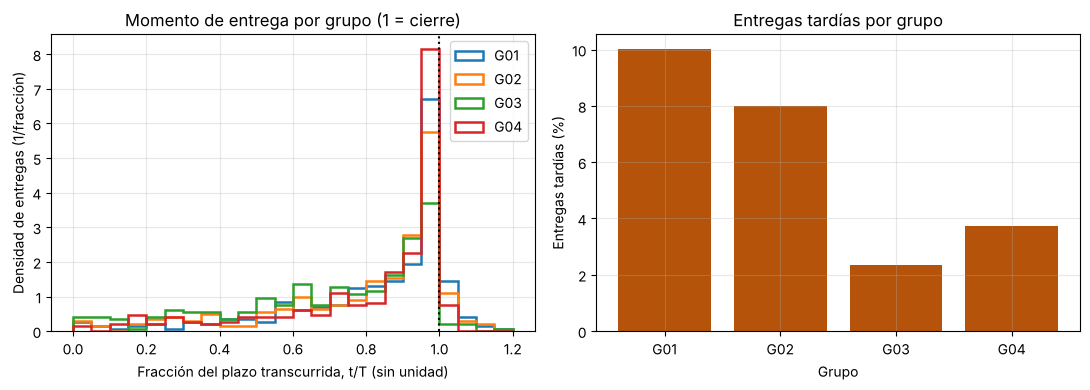

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for g, s in dep.groupby("grupo"):
    ejes[0].hist(s["tau"].clip(upper=1.2), bins=np.linspace(0, 1.2, 25), histtype="step", lw=1.8, density=True, label=g)
ejes[0].axvline(1, color="k", ls=":")
ejes[0].set(xlabel="Fracción del plazo transcurrida, t/T (sin unidad)", ylabel="Densidad de entregas (1/fracción)",
            title="Momento de entrega por grupo (1 = cierre)")
ejes[0].legend()
res_prev = dep.groupby("grupo").agg(tardias=("tardia", "mean"), nota=("nota", "mean"))
ejes[1].bar(res_prev.index, 100 * res_prev["tardias"], color="#b45309")
ejes[1].set(xlabel="Grupo", ylabel="Entregas tardías (%)", title="Entregas tardías por grupo")
for a in ejes: a.grid(alpha=0.3)
fig.tight_layout(); plt.show()

In [6]:
# ¿Se asocian las entregas de último momento con notas más bajas?
dep["ultimas24"] = dep["horas"] >= dep["plazo_h"] - p["ventana_h"]
tabla = dep[~dep.tardia].groupby(["grupo", "ultimas24"])["nota"].mean().unstack()
tabla.columns = ["Antes de las últimas 24 h", "En las últimas 24 h"]
tabla["Diferencia"] = tabla["En las últimas 24 h"] - tabla["Antes de las últimas 24 h"]
tabla

,Antes de las últimas 24 h,En las últimas 24 h,Diferencia
grupo,,,
G01,76.576,69.340,-7.236
G02,78.618,69.554,-9.063
G03,81.210,75.242,-5.968
G04,75.954,71.339,-4.614


En los cuatro grupos las entregas de las últimas 24 h tienen una nota media más baja que las anteriores: entre 4,6 puntos menos (G04) y 9,1 puntos menos (G02). Es coherente con lo que plantea el problema, pero es una asociación observada: no prueba que adelantar la entrega cause la mejora.

## 3. Índice de procrastinación (IP)
Con las entregas **a tiempo**, en proporción del plazo (τ = t/T), se construye F en una malla y se integra 1 − F con el trapecio propio:

$$IP = \frac{1}{T}\int_0^T [1 - F(t)]\,dt = \int_0^1 [1 - F(\tau)]\,d\tau$$

**Verificación:** debe coincidir con el promedio de t/T (integración por partes: E[τ] = ∫(1 − F)). IP = 0 si todo se entrega al abrir y 1 si todo al cierre.

In [7]:
filas = []
for g, s in dep.groupby("grupo"):
    ot = s[~s.tardia]
    filas.append({"grupo": g, "IP (trapecio)": indice_procrastinacion(ot.tau), "promedio de t/T": ot.tau.mean(),
                  "diferencia": abs(indice_procrastinacion(ot.tau) - ot.tau.mean())})
pd.DataFrame(filas)

,grupo,IP (trapecio),promedio de t/T,diferencia
0,G01,0.801,0.801,0.000
1,G02,0.780,0.780,0.000
2,G03,0.700,0.700,0.000
3,G04,0.808,0.808,0.000


## 4. El modelo y su validación
Densidad por descuento hiperbólico, con $k$ en 1/h y $T$ en h:

$$f_k(t) = \frac{k}{\ln(1+kT)\,[1 + k(T-t)]}, \qquad F_k(t) = 1 - \frac{\ln(1+k(T-t))}{\ln(1+kT)}$$

Demostraciones (a mano, en `docs/guia_defensa.md`): $\int_0^T f_k = 1$ y la fracción de las últimas 24 h es $\ln(1+24k)/\ln(1+kT)$.

In [8]:
print("Validación 1: integral de f_k con Simpson, error respecto de 1")
for k, T in [(0.01, 168), (0.1, 168), (0.7, 216), (5.0, 168)]:
    print(f"  k={k:<5} T={T}: error = {abs(simpson(lambda t: densidad_modelo(t, k, T), 0, T, n=20000) - 1):.2e}   (debe ser < 1e-4)")
print("Validación 2: IP del modelo cuando k -> 0 (debe tender a 0,5)")
for k in [1e-2, 1e-4, 1e-6, 1e-9]:
    print(f"  k={k:g}: IP = {ip_modelo(k, 168):.6f}")
print("Validación 3: Simpson contra la fórmula cerrada del IP, 1 + 1/kT - 1/ln(1+kT)")
for k, T in [(0.05, 168), (0.7, 216)]:
    print(f"  k={k}, T={T}: Simpson={ip_modelo(k, T):.8f}  cerrada={ip_modelo_cerrado(k, T):.8f}")

Validación 1: integral de f_k con Simpson, error respecto de 1
  k=0.01  T=168: error = 0.00e+00   (debe ser < 1e-4)
  k=0.1   T=168: error = 5.55e-15   (debe ser < 1e-4)
  k=0.7   T=216: error = 2.17e-11   (debe ser < 1e-4)
  k=5.0   T=168: error = 1.53e-08   (debe ser < 1e-4)
Validación 2: IP del modelo cuando k -> 0 (debe tender a 0,5)
  k=0.01: IP = 0.580851
  k=0.0001: IP = 0.501388
  k=1e-06: IP = 0.500014
  k=1e-09: IP = 0.500000
Validación 3: Simpson contra la fórmula cerrada del IP, 1 + 1/kT - 1/ln(1+kT)
  k=0.05, T=168: Simpson=0.67276044  cerrada=0.67276044
  k=0.7, T=216: Simpson=0.80761652  cerrada=0.80761652


**Verificación con dos formas y error relativo.** Cada integral importante se calcula con un método propio y con otra vía (fórmula exacta, promedio de t/T o `scipy.integrate`, que solo se usa para comparar). Los errores relativos son pequeños en todos los casos.

In [9]:
res_ = resumen_grupo(dep, grupos, p["ventana_h"], p["nota_max"])

In [10]:
from src.reporte import tabla_verificacion

verif = tabla_verificacion(res_, dep, p["ventana_h"])
print("Cada integral importante se obtiene de dos formas; scipy solo se usa para comparar.")
verif.groupby(["integral", "método A", "método B"])["error relativo"].max().to_frame("error relativo máximo (4 grupos)").map("{:.1e}".format)

Cada integral importante se obtiene de dos formas; scipy solo se usa para comparar.


error relativo máximo (4 grupos)
integral                        método A        método B                                                  
IP del modelo (sin unidad)      Simpson propio  fórmula cerrada                                    3.8e-11
                                                scipy.integrate.quad                               3.8e-11
IP observado (sin unidad)       trapecio propio promedio de t/T                                    4.0e-05
                                                scipy.integrate.trapezoid                          0.0e+00
fracción de las últimas 24 h    Simpson propio  fórmula ln(1+hk)/ln(1+kT)                          4.3e-12
∫ f_k dt en [0, T] (sin unidad) Simpson propio  valor exacto                                       2.2e-11

## 5. Estimación de k por bisección
`ip_modelo(k, T)` crece con k, de 0,5 (k → 0) a 1 (k → ∞). Por el **teorema del valor intermedio** hay un único k que iguala el IP del modelo (calculado con Simpson) al observado; la bisección lo encuentra.

In [11]:
res = resumen_grupo(dep, grupos, p["ventana_h"], p["nota_max"])
res[["grupo", "estrategia", "T_h", "ip_obs", "k", "ip_modelo"]]

,grupo,estrategia,T_h,ip_obs,k,ip_modelo
0,G01,Sin intervención,168.000,0.801,0.733,0.801
1,G02,Recordatorio 72 h antes del cierre,168.000,0.780,0.418,0.780
2,G03,Entrega parcial obligatoria a mitad del plazo,168.000,0.700,0.080,0.700
3,G04,Plazo ampliado en 48 h,216.000,0.808,0.706,0.808


## 6. Comparación por grupo: últimas 24 h, tardías y nota media

In [12]:
cols = ["grupo", "ultimas_obs", "ultimas_modelo", "tardias_pct", "nota_media", "horas_docente", "no_entregas_pct"]
comp = res[cols].copy()
comp["error_ultimas24 (pts %)"] = 100 * (comp["ultimas_modelo"] - comp["ultimas_obs"])
comp

,grupo,ultimas_obs,ultimas_modelo,tardias_pct,nota_media,horas_docente,no_entregas_pct,error_ultimas24 (pts %)
0,G01,0.558,0.606,10.035,70.777,0.000,4.934,4.847
1,G02,0.528,0.563,7.986,72.184,0.500,5.263,3.446
2,G03,0.398,0.401,2.365,78.320,6.200,2.632,0.307
3,G04,0.562,0.574,3.741,72.761,1.000,3.289,1.178


In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.arange(len(res))
ax.bar(x - 0.2, 100 * res.ultimas_obs, 0.4, label="Observada", color="#334155")
ax.bar(x + 0.2, 100 * res.ultimas_modelo, 0.4, label="Modelo", color="#0f7b6c")
ax.set_xticks(x, res.grupo); ax.set_xlabel("Grupo"); ax.set_ylabel("Entregas en las últimas 24 h (% de las entregas a tiempo)")
ax.set_title("Últimas 24 h: observada y del modelo"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.show()

El modelo reproduce la fracción de las últimas 24 h con diferencias de entre 0,3 y 4,8 puntos porcentuales. Se ajusta mejor en G03 y G04 que en G01 y G02, donde sobrestima algo la concentración final.

## 7. Decisión

In [14]:
elegida, explicacion = elegir_estrategia(res, p["umbral_nota"])
print(explicacion)
print()
print(texto_recomendacion(res, elegida, explicacion))

{'mejor_nota': 'G03', 'candidatas': ['G03'], 'elegida': 'G03', 'umbral': 1.0, 'diferencia_con_mejor': 0.0}

Aplicar «Entrega parcial obligatoria a mitad del plazo» (G03) en todos los grupos. En el semestre anterior ese grupo obtuvo nota media 78.3, +7.5 puntos respecto a «Sin intervención»; sus entregas tardías fueron 2.4 % (frente a 10.0 %) y solo 40 % de las entregas llegó en las últimas 24 h (frente a 56 %). Costo docente: 6.2 h por tarea, unas 50 h por grupo en 8 tareas.


### Sensibilidad: ¿qué tanto depende la decisión de cómo se traten los datos y del umbral?

In [15]:
sensibilidad_tratamientos(entregas, tareas, grupos, p["ventana_h"], p["nota_max"], p["umbral_nota"])

,caso,G01,G02,G03,G04,elegida
0,"Base: notas >100 ÷10, faltantes excluidas",70.780,72.180,78.320,72.760,G03
1,Notas >100 descartadas,70.780,72.180,78.340,72.760,G03
2,Notas >100 con tope 100,70.780,72.180,78.420,73.040,G03
3,Faltantes con media grupo-tarea,70.780,72.170,78.330,72.760,G03
4,No entregas cuentan como 0,67.280,68.380,76.260,70.370,G03


In [16]:
print("Umbral a partir del cual cambia la estrategia elegida:")
display(umbral_de_cambio(res))
sensibilidad_umbral(res, [0.5, 1, 2, 3, 5, 6, 7, 8])

Umbral a partir del cual cambia la estrategia elegida:


,umbral_puntos,pasa_a
0,5.560,G04
1,6.140,G02
2,7.540,G01


,umbral_puntos,elegida
0,0.500,G03
1,1.000,G03
2,2.000,G03
3,3.000,G03
4,5.000,G03
5,6.000,G04
6,7.000,G02
7,8.000,G01


In [17]:
for rival in ["G04", "G02", "G01"]:
    d, lo, hi = bootstrap_diferencia(dep, elegida, rival)
    print(f"{elegida} - {rival}: {d:5.2f} puntos, intervalo del 95 %: [{lo:5.2f}, {hi:5.2f}]")

G03 - G04:  5.51 puntos, intervalo del 95 %: [ 1.07,  9.89]
G03 - G02:  6.04 puntos, intervalo del 95 %: [ 1.24, 10.79]


G03 - G01:  7.70 puntos, intervalo del 95 %: [ 3.17, 12.16]


**Lectura.** La decisión no cambia con ningún tratamiento de datos probado. El parámetro que más la mueve es la diferencia mínima de nota: con la regla del curso (1 punto) gana G03, pero si el cliente aceptara perder más de 5,6 puntos de nota media para ahorrar horas docentes, pasaría a G04. Este umbral es lo que más importa discutir con la coordinación.

**Limitaciones.**
- Los grupos no se asignaron al azar: parte de la diferencia puede venir de diferencias entre los estudiantes y no solo de la estrategia.
- G03 es la estrategia más cara (6,2 h docentes por tarea); además, la entrega parcial obliga a trabajar antes del cierre, así que parte de su efecto en la nota puede ser trabajo adicional y no solo menos procrastinación.
- Las entregas que no existen no están en la base; contadas como 0, G03 sigue ganando.
- El modelo de un solo parámetro k ajusta bien el IP por construcción, pero sobrestima las entregas de las últimas 24 h en G01 y G02.
- Es un solo semestre con 38 estudiantes por grupo.

**¿Qué tendría que ocurrir para que la recomendación deje de ser válida?** Que el costo docente de G03 no se pueda sostener, que el cliente fije un umbral de diferencia de nota mayor que 5,6 puntos, o que un nuevo semestre no reproduzca la ventaja de G03 en nota y en tardías.

**¿Cómo se mediría el resultado?** Con los mismos cuatro indicadores del semestre siguiente: IP, fracción de entregas de las últimas 24 h, porcentaje de tardías y nota media, más las horas docentes realmente usadas.